# Community 2: Protein Sequence Classification

**Disclaimer: This is uploaded from a github user, not the KAN authors. KAN authors did not writer this or proofread this carefully, hence are not responsible for mistakes in this notebook. If you have questions, please consult the github user who uploaded it. Thank you!**

In this example, we will see how to use KAN in protein sequence classification. We will be using one hot encoding to encode the amino acids.

#### This is just an example how it can be used for protein sequences. Need to use real data to actually observe the performance.

In [1]:
from xkan import KANNetwork, fit
import torch
import random
import numpy as np

In [2]:
# Hyperparameters
PROTEIN_WINDOW_SIZE = 5 

# define the universe of possible input amino acids, ie. vocab list
aa_list = 'ARNDCQEGHILKMFPSTWYVX'

In [3]:
def one_hot_encode(protein_sequence):
    """
    One-hot encodes a protein sequence.

    Args:
        protein_sequence (str): The input protein sequence.

    Returns:
        numpy.array: The one-hot encoded representation of the protein sequence.
    """
    # Create a dictionary mapping amino acids to indices
    aa_to_index = {aa: i for i, aa in enumerate(aa_list)}
    
    # Initialize an array of zeros with shape (sequence_length, alphabet_length)
    encoding = np.zeros((len(protein_sequence), len(aa_list)))
    
    # Iterate over the protein sequence and set the corresponding index to 1
    for i, aa in enumerate(protein_sequence):
        if aa in aa_to_index:
            encoding[i, aa_to_index[aa]] = 1
        else:
            # If the amino acid is not in the alphabet, set the last index to 1 (unknown)
            encoding[i, -1] = 1
    
    return encoding

In [4]:
def generate_sample_protein_dataset(num_samples=20, protein_window_size=5):
    """
    Generate a dataset of protein sequences of length 11, keeping Lysine(K) in the center for label 1 and Serine(S) for label 0. 

    Args:
        num_samples (int): Number of samples to generate.
        protein_window_size (int): Length of the protein sequence.

    Returns:
        (dict, dict): the training and test sets, the inputs under 'x' and the labels under 'y'.
    """
    
    train, test = {'x': [], 'y': []}, {'x': [], 'y': []}
    alphabet = 'ARNDCQEGHILKMFPSTWYVX'

    # Generate half of the samples with label 1 and half with label 0
    label_sequence = [1] * (num_samples // 2) + [0] * (num_samples // 2)
    random.shuffle(label_sequence)

    for label in label_sequence:
        # Generate a protein sequence with 'K' in the middle for label 1 and 'S' for label 0
        if label == 1:
            center_aa = 'K'
        else:
            center_aa = 'S'
        sequence = ''.join(random.choices(alphabet.replace(center_aa, ''), k=protein_window_size//2)) + center_aa + ''.join(random.choices(alphabet.replace(center_aa, ''), k=protein_window_size//2))
        print(sequence, label)
        encoded_sequence = one_hot_encode(sequence).flatten()

        # Split the dataset into train and test (50% each)
        if len(train['x']) < num_samples // 2:
            train['x'].append(encoded_sequence)
            train['y'].append(label)
        else:
            test['x'].append(encoded_sequence)
            test['y'].append(label)

    # Convert lists to tensors
    for data in (train, test):
        data['x'] = torch.tensor(np.array(data['x']))
        data['y'] = torch.tensor(data['y']).view(-1, 1)

    return train, test

# Generate dataset with 10 samples
train, test = generate_sample_protein_dataset(40)

HYKPN 1
RISTP 0
MHKAT 1
FQSMK 0
ADKMQ 1
TLKQT 1
RQSDF 0
CASMQ 0
NDKRC 1
AKSHN 0
FISNL 0
QISCC 0
NYSFG 0
LSKXP 1
HRKCL 1
ETKVD 1
ELKEG 1
MCSQW 0
NYSKF 0
LHSFQ 0
AQKGR 1
YDKWL 1
LEKDE 1
MASCP 0
PPKQR 1
FYKTM 1
CGSYL 0
PAKRD 1
DHKSC 1
AQSWN 0
PGKSG 1
KMSKP 0
SFKEI 1
QFSAW 0
HKSAP 0
RXSDR 0
FQKNG 1
THSRC 0
VGKTR 1
XHSIX 0


In [5]:
print(train)
print(test)

{'x': tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 1., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 1.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]], dtype=torch.float64), 'y': tensor([[1],
        [0],
        [1],
        [0],
        [1],
        [1],
        [0],
        [0],
        [1],
        [0],
        [0],
        [0],
        [0],
        [1],
        [1],
        [1],
        [1],
        [0],
        [0],
        [0]])}
{'x': tensor([[1., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 1.]], dtype=torch.float64), 'y': tensor([[1],
        [1],
        [1],
        [0],
        [1],
        [1],
        [0],
        [1],
        [1],
        [0],
        [1],
        [0],
        

In [6]:
# define model
# create a KAN: 105 inputs, 2D output, and 3 hidden neurons. k=2, 3 grid intervals (grid=3).
# considering window size: 5, 5 times 21(vocab size), input-> 21 * 5

model = KANNetwork([105, 3, 2], grid=3, k=2)

In [7]:
def train_acc():
    return torch.mean((torch.round(model(train['x'])[:,0]) == train['y'][:,0]).float())

def test_acc():
    return torch.mean((torch.round(model(test['x'])[:,0]) == test['y'][:,0]).float())

# the squared error of both outputs against the label (broadcast, as the old default loss did); accuracies afterwards
history = fit(model, train, test, steps=5, loss=lambda pred, target: torch.mean((pred - target) ** 2))
print('train loss: %.2e | test loss: %.2e' % (np.sqrt(history['train/y'][-1]), np.sqrt(history['val/y'][-1])))
train_acc().item(), test_acc().item()

train loss: 1.29e-03 | test loss: 2.58e-01


(1.0, 0.8999999761581421)

In [8]:
from xkan.symbolic import auto_symbolic
lib = ['x','x^2']

auto_symbolic(model, train['x'], lib=lib)

fixing (0,0,0) with x^2, r2=0.9999987483024597, c=2
fixing (0,0,1) with x, r2=0.9999902248382568, c=1
fixing (0,0,2) with x, r2=0.9999722242355347, c=1
fixing (0,1,0) with x^2, r2=1.0000004768371582, c=2
fixing (0,1,1) with x^2, r2=0.9999572038650513, c=2
fixing (0,1,2) with x^2, r2=0.9999934434890747, c=2
fixing (0,2,0) with x, r2=0.9999837875366211, c=1
fixing (0,2,1) with x, r2=0.9999857544898987, c=1
fixing (0,2,2) with x^2, r2=0.9999995231628418, c=2
fixing (0,3,0) with x, r2=0.0, c=1
fixing (0,3,1) with x, r2=0.0, c=1
fixing (0,3,2) with x, r2=0.0, c=1
fixing (0,4,0) with x, r2=0.9999838471412659, c=1
fixing (0,4,1) with x, r2=0.9999219179153442, c=1
fixing (0,4,2) with x, r2=0.9999396204948425, c=1
fixing (0,5,0) with x^2, r2=0.999999463558197, c=2
fixing (0,5,1) with x^2, r2=1.0000005960464478, c=2
fixing (0,5,2) with x, r2=0.9999598264694214, c=1
fixing (0,6,0) with x^2, r2=0.9999887943267822, c=2
fixing (0,6,1) with x, r2=0.9998659491539001, c=1
fixing (0,6,2) with x, r2=0.99

fixing (0,18,0) with x, r2=0.0, c=1
fixing (0,18,1) with x, r2=0.0, c=1
fixing (0,18,2) with x, r2=0.0, c=1
fixing (0,19,0) with x, r2=0.0, c=1
fixing (0,19,1) with x, r2=0.0, c=1
fixing (0,19,2) with x, r2=0.0, c=1


fixing (0,20,0) with x, r2=0.0, c=1
fixing (0,20,1) with x, r2=0.0, c=1
fixing (0,20,2) with x, r2=0.0, c=1
fixing (0,21,0) with x, r2=0.9999856352806091, c=1
fixing (0,21,1) with x, r2=0.9999663829803467, c=1
fixing (0,21,2) with x^2, r2=0.9999873042106628, c=2
fixing (0,22,0) with x^2, r2=1.0000001192092896, c=2
fixing (0,22,1) with x^2, r2=0.9999616742134094, c=2
fixing (0,22,2) with x^2, r2=1.0000001192092896, c=2
fixing (0,23,0) with x, r2=0.0, c=1
fixing (0,23,1) with x, r2=0.0, c=1
fixing (0,23,2) with x, r2=0.0, c=1
fixing (0,24,0) with x, r2=0.9999833703041077, c=1
fixing (0,24,1) with x^2, r2=1.0000009536743164, c=2
fixing (0,24,2) with x, r2=0.9999974966049194, c=1
fixing (0,25,0) with x^2, r2=1.000000238418579, c=2
fixing (0,25,1) with x, r2=0.9998692274093628, c=1
fixing (0,25,2) with x, r2=0.9998983144760132, c=1
fixing (0,26,0) with x, r2=0.9999776482582092, c=1
fixing (0,26,1) with x, r2=0.9999276995658875, c=1
fixing (0,26,2) with x^2, r2=1.0000011920928955, c=2
fixing

fixing (0,38,0) with x, r2=0.0, c=1
fixing (0,38,1) with x, r2=0.0, c=1
fixing (0,38,2) with x, r2=0.0, c=1
fixing (0,39,0) with x, r2=0.9999967217445374, c=1
fixing (0,39,1) with x^2, r2=1.0000004768371582, c=2
fixing (0,39,2) with x, r2=0.9999346137046814, c=1


fixing (0,40,0) with x, r2=0.0, c=1
fixing (0,40,1) with x, r2=0.0, c=1
fixing (0,40,2) with x, r2=0.0, c=1
fixing (0,41,0) with x, r2=0.0, c=1
fixing (0,41,1) with x, r2=0.0, c=1
fixing (0,41,2) with x, r2=0.0, c=1
fixing (0,42,0) with x, r2=0.0, c=1
fixing (0,42,1) with x, r2=0.0, c=1
fixing (0,42,2) with x, r2=0.0, c=1
fixing (0,43,0) with x, r2=0.0, c=1
fixing (0,43,1) with x, r2=0.0, c=1
fixing (0,43,2) with x, r2=0.0, c=1
fixing (0,44,0) with x, r2=0.0, c=1
fixing (0,44,1) with x, r2=0.0, c=1
fixing (0,44,2) with x, r2=0.0, c=1
fixing (0,45,0) with x, r2=0.0, c=1
fixing (0,45,1) with x, r2=0.0, c=1
fixing (0,45,2) with x, r2=0.0, c=1
fixing (0,46,0) with x, r2=0.0, c=1
fixing (0,46,1) with x, r2=0.0, c=1
fixing (0,46,2) with x, r2=0.0, c=1
fixing (0,47,0) with x, r2=0.0, c=1
fixing (0,47,1) with x, r2=0.0, c=1
fixing (0,47,2) with x, r2=0.0, c=1
fixing (0,48,0) with x, r2=0.0, c=1
fixing (0,48,1) with x, r2=0.0, c=1
fixing (0,48,2) with x, r2=0.0, c=1
fixing (0,49,0) with x, r2=0

fixing (0,57,0) with x, r2=0.9999973773956299, c=1
fixing (0,57,1) with x, r2=0.9999974370002747, c=1
fixing (0,57,2) with x, r2=1.0000003576278687, c=1
fixing (0,58,0) with x, r2=0.0, c=1
fixing (0,58,1) with x, r2=0.0, c=1
fixing (0,58,2) with x, r2=0.0, c=1


... (2 outputs left out)

fixing (0,75,2) with x, r2=0.9999850988388062, c=1
fixing (0,76,0) with x, r2=0.9999707341194153, c=1
fixing (0,76,1) with x, r2=0.9999974370002747, c=1
fixing (0,76,2) with x, r2=0.9999931454658508, c=1
fixing (0,77,0) with x^2, r2=1.0000001192092896, c=2
fixing (0,77,1) with x^2, r2=1.0000014305114746, c=2
fixing (0,77,2) with x, r2=0.9999412298202515, c=1
fixing (0,78,0) with x, r2=0.0, c=1
fixing (0,78,1) with x, r2=0.0, c=1
fixing (0,78,2) with x, r2=0.0, c=1
fixing (0,79,0) with x^2, r2=1.0000011920928955, c=2
fixing (0,79,1) with x^2, r2=1.000001311302185, c=2
fixing (0,79,2) with x^2, r2=1.0000020265579224, c=2
fixing (0,80,0) with x, r2=0.0, c=1
fixing (0,80,1) with x, r2=0.0, c=1
fixing (0,80,2) with x, r2=0.0, c=1
fixing (0,81,0) with x, r2=0.0, c=1
fixing (0,81,1) with x, r2=0.0, c=1
fixing (0,81,2) with x, r2=0.0, c=1
fixing (0,82,0) with x^2, r2=0.9999997615814209, c=2
fixing (0,82,1) with x, r2=0.9998987317085266, c=1
fixing (0,82,2) with x, r2=0.9999518990516663, c=1
fi

fixing (0,91,0) with x^2, r2=0.9999997019767761, c=2
fixing (0,91,1) with x, r2=0.999979555606842, c=1
fixing (0,91,2) with x^2, r2=1.0000003576278687, c=2
fixing (0,92,0) with x, r2=0.0, c=1
fixing (0,92,1) with x, r2=0.0, c=1


fixing (0,92,2) with x, r2=0.0, c=1
fixing (0,93,0) with x, r2=0.0, c=1
fixing (0,93,1) with x, r2=0.0, c=1
fixing (0,93,2) with x, r2=0.0, c=1
fixing (0,94,0) with x, r2=0.9999255537986755, c=1
fixing (0,94,1) with x^2, r2=0.9999939203262329, c=2
fixing (0,94,2) with x, r2=0.9998908042907715, c=1
fixing (0,95,0) with x^2, r2=0.9999986886978149, c=2
fixing (0,95,1) with x, r2=0.9999338388442993, c=1
fixing (0,95,2) with x^2, r2=1.0000015497207642, c=2
fixing (0,96,0) with x, r2=0.0, c=1
fixing (0,96,1) with x, r2=0.0, c=1
fixing (0,96,2) with x, r2=0.0, c=1
fixing (0,97,0) with x, r2=0.9999420046806335, c=1
fixing (0,97,1) with x, r2=0.9999813437461853, c=1
fixing (0,97,2) with x^2, r2=0.9999977946281433, c=2
fixing (0,98,0) with x, r2=0.9999837875366211, c=1
fixing (0,98,1) with x, r2=0.9999235272407532, c=1
fixing (0,98,2) with x, r2=0.9999842643737793, c=1
fixing (0,99,0) with x, r2=0.0, c=1
fixing (0,99,1) with x, r2=0.0, c=1
fixing (0,99,2) with x, r2=0.0, c=1
fixing (0,100,0) wit

{(0, 0, 0): ('x^2', np.float64(0.9999987483024597), np.int64(2)),
 (0, 0, 1): ('x', np.float64(0.9999902248382568), np.int64(1)),
 (0, 0, 2): ('x', np.float64(0.9999722242355347), np.int64(1)),
 (0, 1, 0): ('x^2', np.float64(1.0000004768371582), np.int64(2)),
 (0, 1, 1): ('x^2', np.float64(0.9999572038650513), np.int64(2)),
 (0, 1, 2): ('x^2', np.float64(0.9999934434890747), np.int64(2)),
 (0, 2, 0): ('x', np.float64(0.9999837875366211), np.int64(1)),
 (0, 2, 1): ('x', np.float64(0.9999857544898987), np.int64(1)),
 (0, 2, 2): ('x^2', np.float64(0.9999995231628418), np.int64(2)),
 (0, 3, 0): ('x', np.float64(0.0), np.int64(1)),
 (0, 3, 1): ('x', np.float64(0.0), np.int64(1)),
 (0, 3, 2): ('x', np.float64(0.0), np.int64(1)),
 (0, 4, 0): ('x', np.float64(0.9999838471412659), np.int64(1)),
 (0, 4, 1): ('x', np.float64(0.9999219179153442), np.int64(1)),
 (0, 4, 2): ('x', np.float64(0.9999396204948425), np.int64(1)),
 (0, 5, 0): ('x^2', np.float64(0.999999463558197), np.int64(2)),
 (0, 5, 1)

In [9]:
from xkan.symbolic import symbolic_formula
from xkan.utils import ex_round
formula1, formula2 = symbolic_formula(model)[0]
ex_round(formula1, 2)

0.08*x_1 + 0.05*x_101 - 0.05*x_102 + 0.06*x_11 - 0.03*x_14 - 0.05*x_22 + 0.07*x_25 - 0.05*x_26 - 0.02*x_27 + 0.03*x_3 + 0.03*x_30 - 0.06*x_31 + 0.04*x_32 + 0.06*x_33 + 0.03*x_37 + 0.02*x_38 + 0.01*x_40 - 0.06*x_5 + 0.31*x_54 - 0.16*x_58 - 0.04*x_6 + 0.03*x_64 + 0.03*x_65 + 0.04*x_68 - 0.03*x_69 + 0.04*x_7 + 0.02*x_72 - 0.05*x_75 - 0.04*x_76 + 0.04*x_77 + 0.03*x_78 + 0.07*x_83 + 0.04*x_84 + 0.02*x_87 + 0.02*x_89 + 0.06*x_9 + 0.01*x_90 + 0.04*x_92 + 0.01*x_95 - 0.04*x_96 - 0.04*x_98 + 0.01*x_99 + 0.37

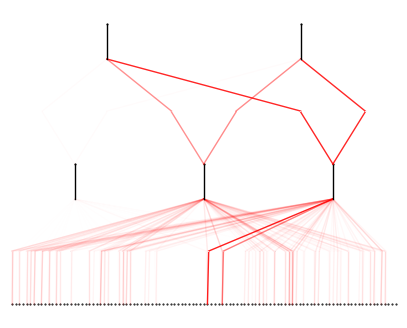

In [10]:
from xkan.viz import plot
plot(model, train['x']);